# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
!pip install ucimlrepo --quiet
from ucimlrepo import fetch_ucirepo

# fetch dataset
student_performance = fetch_ucirepo(id=320)

df = pd.concat([student_performance.data.features, student_performance.data.targets], axis=1)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o dataset Student Performance tem 32 variáveis preditoras (idade, tempo de estudo, faltas, suporte familiar, notas parciais, entre outras) mais o alvo (G3, a nota final do aluno).

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(649, 33)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [ ]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra a nota final (G3) em uma escala numérica de 0 a 20. Pra hoje, vamos simplificar para uma variável categórica binária, aprovação (nota $\ge$ 10) ou reprovação (nota < 10), já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = aprovado, roxo = reprovado).

In [ ]:
df["situacao"] = np.where(df["G3"] >= 10, "Aprovado", "Reprovado")

# Verificando o balanceamento da nossa nova classe alvo
print(df["situacao"].value_counts())

df.head()

situacao
Aprovado     549
Reprovado    100
Name: count, dtype: int64


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,situacao
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,Aprovado
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,Aprovado
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,Aprovado
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,Aprovado
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,Aprovado


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Nenhum dado ausente

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai orientar as decisões de tratamento na próxima seção. Por exemplo, se uma variável for muito assimétrica (como costuma ser o número de faltas), faz mais sentido imputar eventuais dados ausentes com a mediana do que com a média.

In [ ]:
# Separando as variáveis quantitativas (contínuas/discretas) e as qualitativas (nominais/ordinais)
VARS_QUANT = ["age", "absences", "G1", "G2", "G3"] # Incluímos as notas e faltas
VARS_QUALI = ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
              "reason", "guardian", "schoolsup", "famsup", "paid", "activities",
              "nursery", "higher", "internet", "romantic", "Medu", "Fedu",
              "traveltime", "studytime", "failures", "famrel", "freetime",
              "goout", "Dalc", "Walc", "health"]

### Tabela descritiva, com assimetria e curtose
# Calculamos as estatísticas apenas para as variáveis quantitativas
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,16.74,17.00,1.22,15.00,22.00,0.42,0.07
absences,3.66,2.00,4.64,0.00,32.00,2.02,5.78
G1,11.40,11.00,2.75,0.00,19.00,-0.00,0.04
G2,11.57,11.00,2.91,0.00,19.00,-0.36,1.66
G3,11.91,12.00,3.23,0.00,19.00,-0.91,2.71


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

**Resposta:**


*   Idade: Assimetria razoável
*   Faltas: Assimetria alta e curtose leptocúrtica
*   Nota G3: Assimetria moderada e curtose leptocúrtica


### Distribuições de dados

Onde fizer sentido, compararemos "Aprovado" (rosa) vs. "Reprovado" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


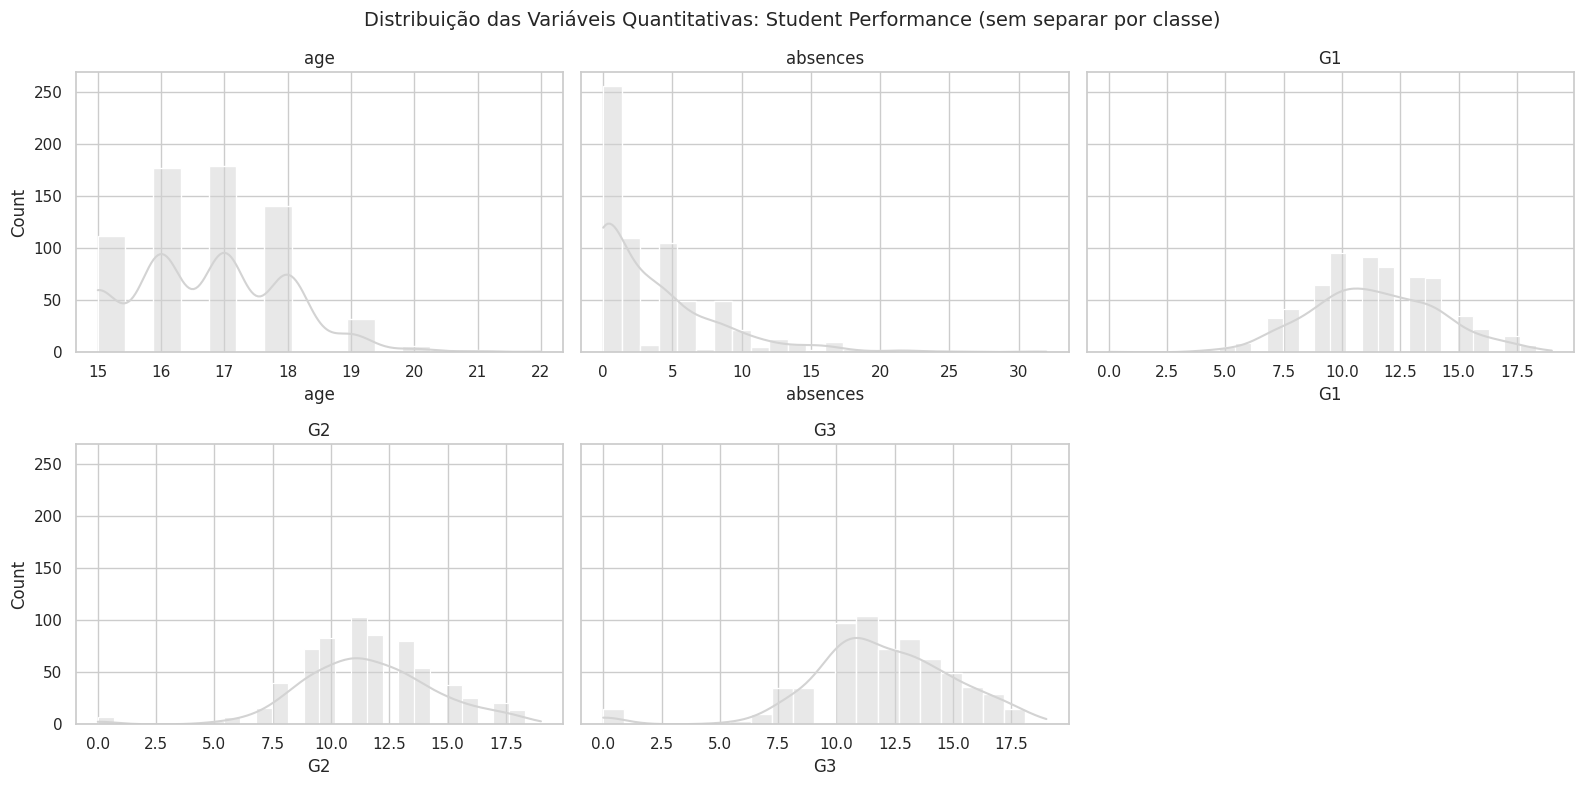

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Student Performance (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

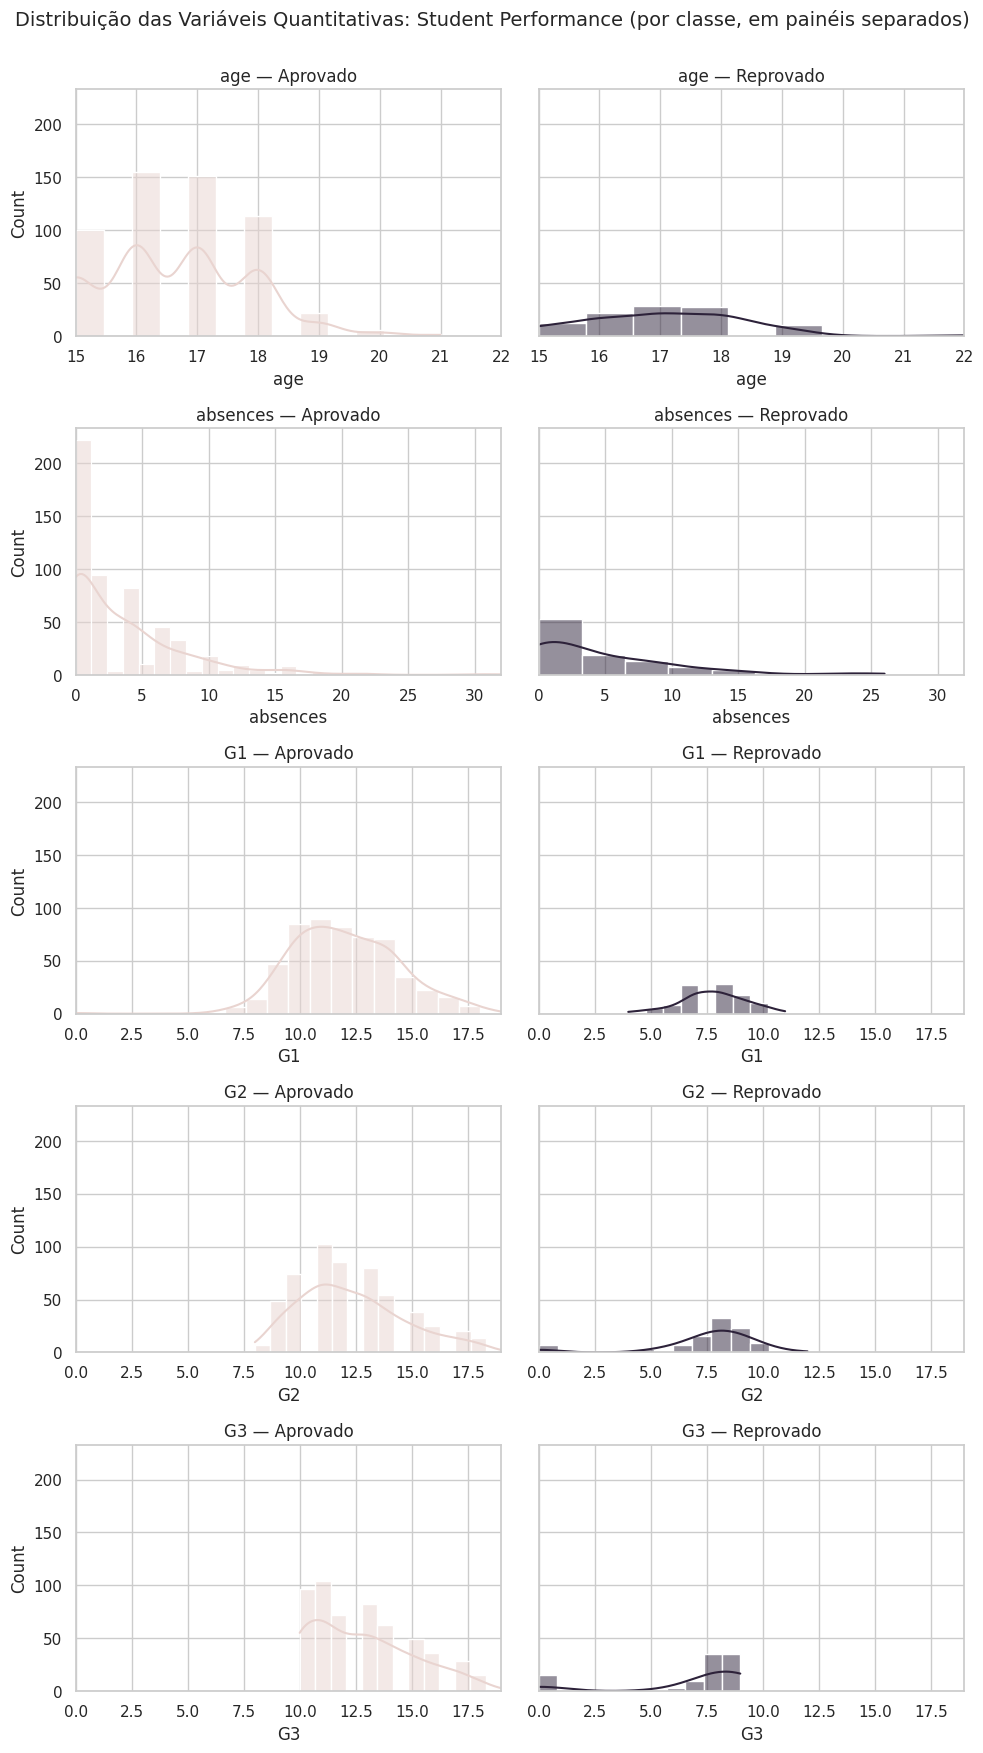

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())

    for j, (classe, cor) in enumerate([("Aprovado", COR_CONTEXTO), ("Reprovado", COR_DESTAQUE)]):
        subset = df[df["situacao"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Student Performance (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Aprovado" e "Reprovado"?

**Respostas**: Sim, principalmente das notas G1, G2 e G3.

Além disso,

#### Testes de Aderência

*Será que o número de faltas (absences) segue uma distribuição normal?*

O Shapiro-Wilk é o teste de aderência mais usado para normalidade, junto com o QQ-Plot como visualização de apoio. Vamos testar com a variável absences (embora você possa facilmente trocar para G3 se quiser testar a normalidade das notas finais).

Shapiro-Wilk — absences: estatística=0.7717, p-valor=4.522e-29)
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


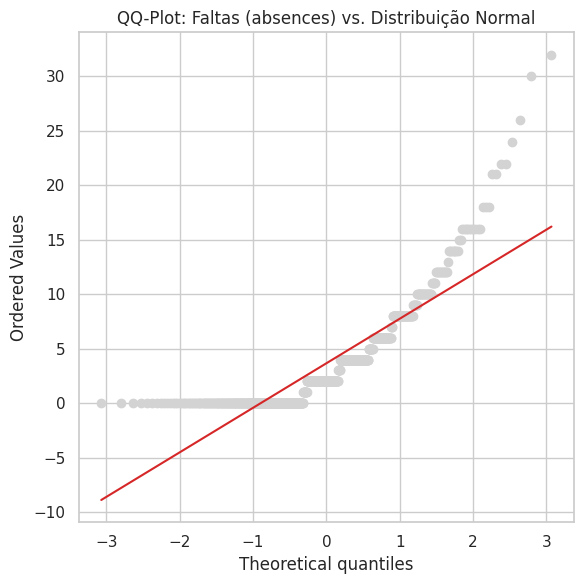

In [ ]:
from scipy import stats
# Teste de aderência (Shapiro-Wilk) para a variável absences
stat_sw, p_valor_sw = stats.shapiro(df["absences"].dropna())
print(f"Shapiro-Wilk — absences: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g})")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

### QQ-Plot — Faltas (absences)
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["absences"].dropna(), dist="norm", plot=ax)

# Configurando as cores do gráfico para manter o padrão visual da aula
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title("QQ-Plot: Faltas (absences) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos se afastarem muito da reta vermelha nas pontas, indicam caudas mais pesadas ou mais leves que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade, mas é o contrário. Amostras pequenas têm menos poder estatístico, ou seja, tendem a não rejeitar a hipótese nula mesmo quando os dados realmente não são normais. Já amostras muito grandes (milhares de linhas) deixam o teste sensível demais, rejeitando a normalidade por desvios triviais. Com nosso tamanho de amostra ($n = 649$ alunos), que não é nem pequeno nem gigante, e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não apenas um artefato do tamanho da amostra.  

- **Como afirmar o resultado:** quando o teste rejeita H0 (nosso caso, $p < 0.05$), a afirmação correta é "temos evidência estatística contra a normalidade", que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste não rejeita H0, já que a ausência de rejeição nunca prova que os dados são perfeitamente normais, apenas mostra que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
age,0.9156,0.000000,True
absences,0.7717,0.000000,True
G1,0.9855,0.000005,True
G2,0.9617,0.000000,True
G3,0.9260,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (absences, faltas), só pra fixar como essa visualização se lê.

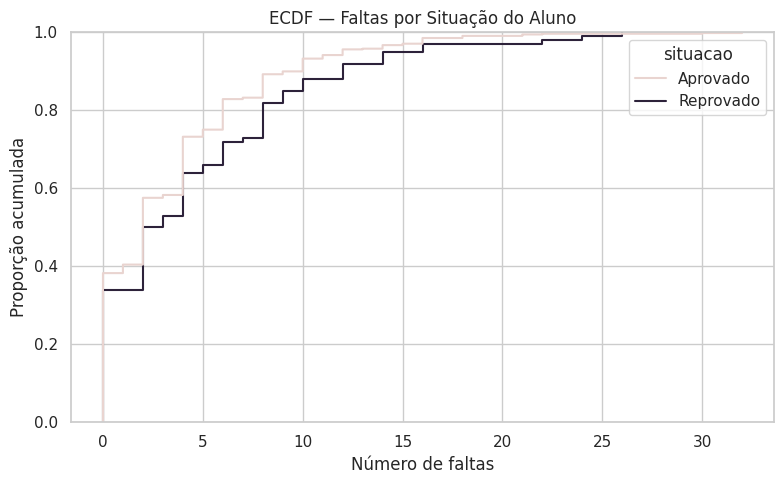

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="absences", hue="situacao",
             palette={"Aprovado": COR_CONTEXTO, "Reprovado": COR_DESTAQUE})
plt.title("ECDF — Faltas por Situação do Aluno")
plt.xlabel("Número de faltas")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos alunos desse grupo tem faltas até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de faltas onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

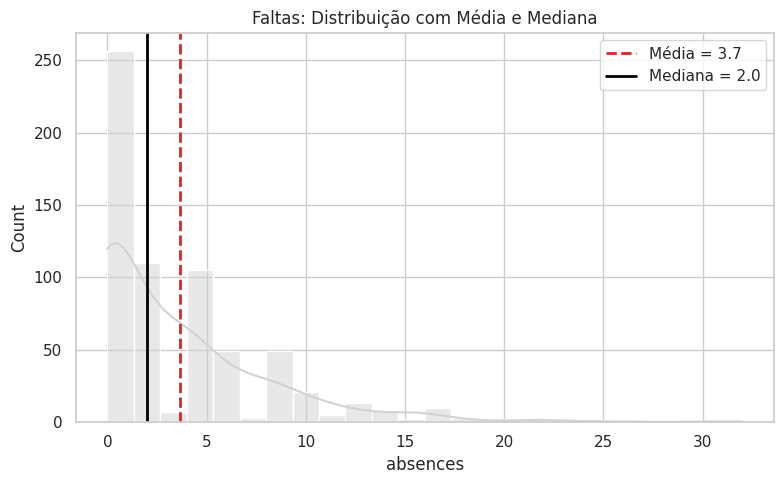

In [ ]:
media_absences = df["absences"].mean()
mediana_absences = df["absences"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="absences", kde=True, color=COR_NEUTRA)
plt.axvline(media_absences, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_absences:.1f}")
plt.axvline(mediana_absences, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_absences:.1f}")
plt.title("Faltas: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

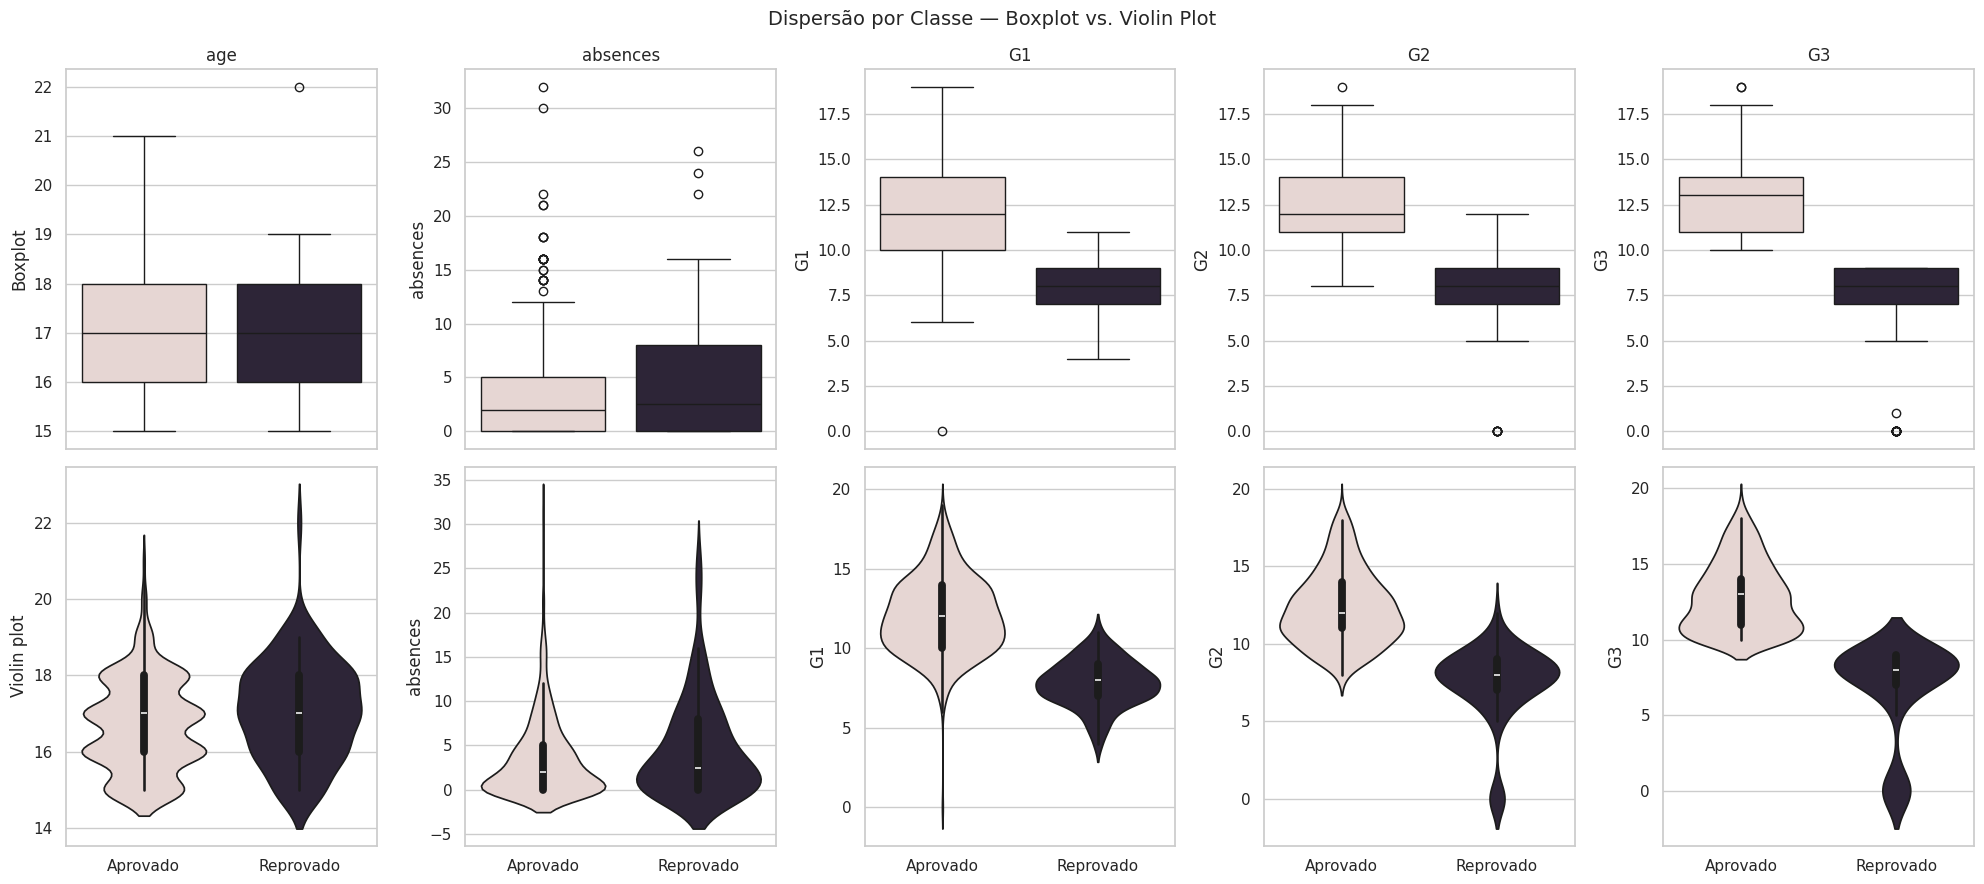

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Aprovado": COR_CONTEXTO, "Reprovado": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="situacao", y=col, hue="situacao",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="situacao", y=col, hue="situacao",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Aprovado" e "Reprovado"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

**Resposta:** Sim, isso fica nítido nas variáveis de notas passadas (G1 e G2). A "caixa" (IQR) e a mediana dessas variáveis são visivelmente mais baixas para o grupo Reprovado em comparação ao Aprovado. Isso indica, logo de cara, uma forte correlação linear: quem vai mal no início do ano tende a reprovar no final. Além disso, a caixa de faltas (absences) no grupo reprovado costuma ser um pouco mais "esticada" para cima, indicando maior dispersão e acúmulo de faltas.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava para decidir como tratar os outliers das variáveis quantitativas (já que, como vimos no Princípio Estrutural, nosso dataset não possui dados ausentes). Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") para confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
age,13.0,21.0,1.0
absences,-9.0,15.0,21.0
G1,5.5,17.5,16.0
G2,5.5,17.5,25.0
G3,4.0,20.0,16.0


### Visualizando os Outliers

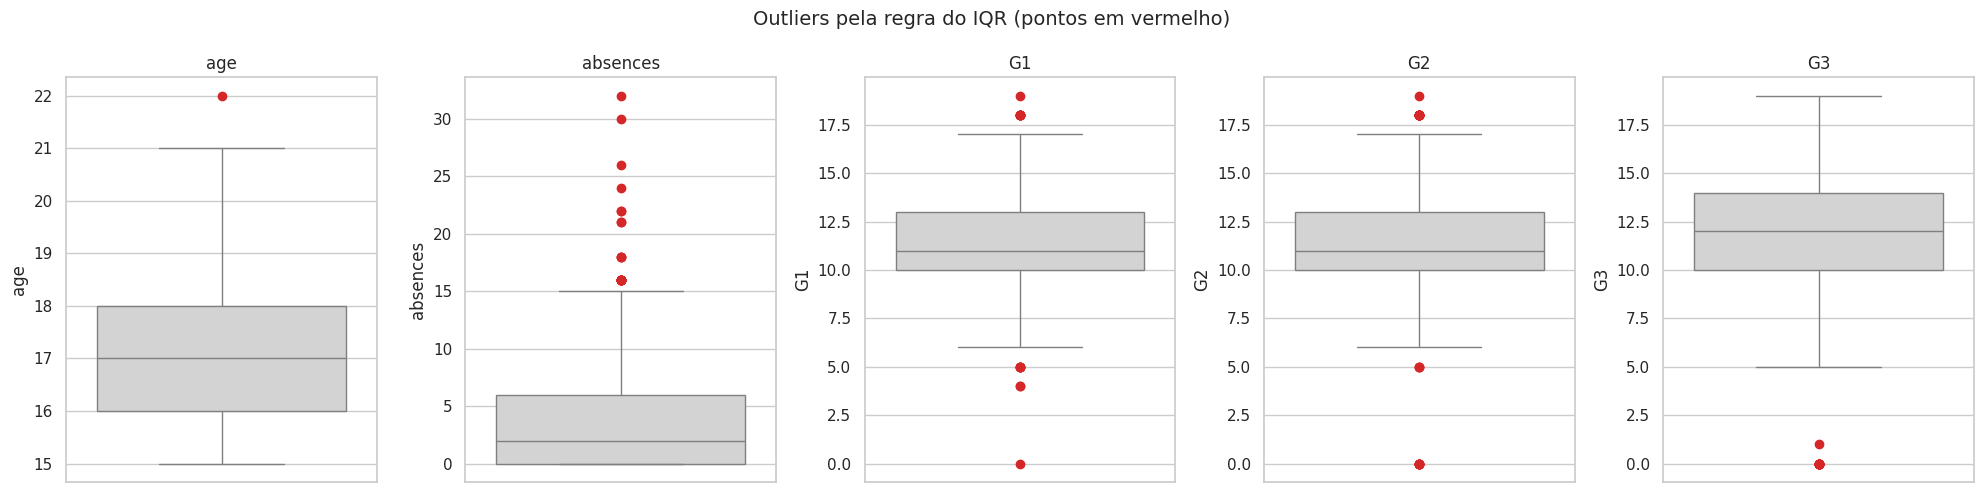

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `absences` e `age`): eles parecem plausíveis no contexto educacional (alunos reais podem acumular muitas faltas durante o ano ou ser mais velhos devido a repetências), ou parecem violar algum limite lógico conhecido (como uma nota fora da escala de 0 a 20 ou uma idade negativa)? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.


**Resposta**: Eles são Outliers Estatísticos Legítimos. Alunos com um número alto de faltas ou com idade avançada (devido a repetências) representam casos reais e comuns no ambiente escolar, não são erros de digitação. Portanto, a recomendação é manter esses dados. Removê-los seria apagar o perfil exato do aluno que muitas vezes acaba reprovando.

### Decidindo o Tratamento dos Dados Ausentes

Como verificamos anteriormente no df.info(), nosso dataset não possui dados ausentes. Portanto, pularemos esta etapa e iremos direto para o tratamento de outliers.

### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas plausíveis no contexto escolar, ainda que atípicas), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser educacionalmente relevante — por exemplo, exatamente os alunos com o número de faltas mais extremo podem ser os de maior risco de reprovação) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `absences` (faltas) — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo preditivo.

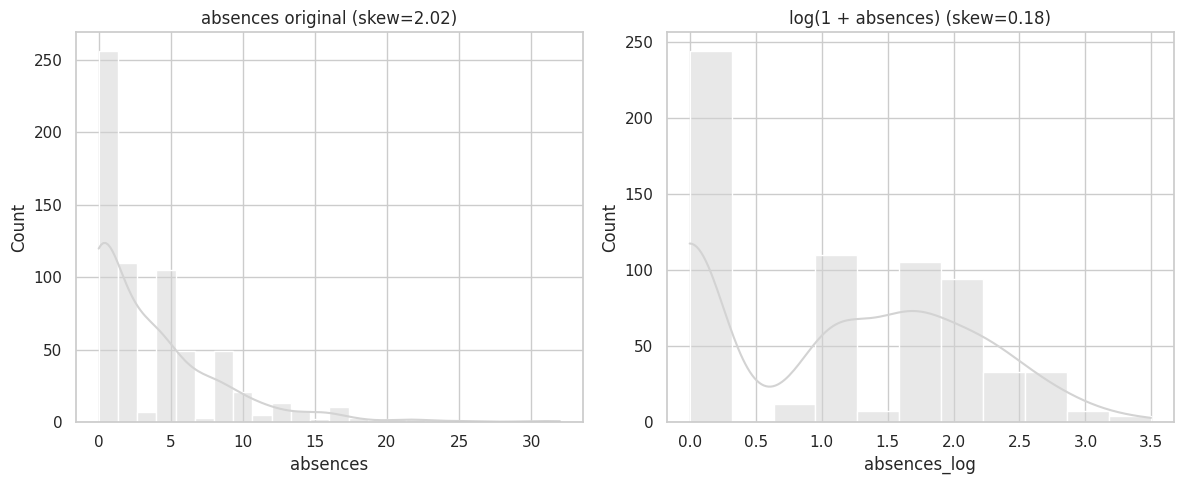

In [ ]:
df["absences_log"] = np.log1p(df["absences"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="absences", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"absences original (skew={df['absences'].skew():.2f})")

sns.histplot(data=df, x="absences_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + absences) (skew={df['absences_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `absences_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

**Resposta:**
Sim, a redução é visível. A transformação "encolheu" a cauda longa dos alunos com muitas faltas, centralizando mais os dados e reduzindo o valor numérico da assimetria (skew) para bem mais perto de zero.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: verificamos que não havia dados ausentes e decidimos manter os outliers originais por serem legítimos. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

(Nota: como optamos por não remover linhas ou imputar valores, os resultados serão idênticos, confirmando que mantivemos a estrutura original dos dados intacta).

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,16.74,17.00,1.22,15.00,22.00,0.42,0.07
absences,3.66,2.00,4.64,0.00,32.00,2.02,5.78
G1,11.40,11.00,2.75,0.00,19.00,-0.00,0.04
G2,11.57,11.00,2.91,0.00,19.00,-0.36,1.66
G3,11.91,12.00,3.23,0.00,19.00,-0.91,2.71


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
age,0.417,0.417,0.072,0.072,0.0,0.0
absences,2.021,2.021,5.781,5.781,0.0,0.0
G1,-0.003,-0.003,0.037,0.037,0.0,0.0
G2,-0.360,-0.360,1.662,1.662,0.0,0.0
G3,-0.913,-0.913,2.712,2.712,0.0,0.0


**Pra discutir:** os valores mudaram alguma coisa? Fazia sentido esperar alguma diferença, considerando que nosso dataset não tinha dados ausentes (removemos **0** linhas) e decidimos não alterar/deletar nenhum outlier? Esse resultado (**nenhuma** mudança, deltas **zerados**) é, na verdade, uma confirmação de que nossos dados originais já estavam completos e de que nosso tratamento foi seguro — não um sinal de que essa etapa da EDA foi inútil.

**Resposta:**

Os valores não mudaram absolutamente nada (os deltas ficaram em 0.000). Isso era 100% esperado e desejado, já que não precisamos descartar nenhuma linha e decidimos manter os outliers legítimos. Isso comprova que preservamos a integridade total dos dados originais.

**As faltas (absences) ainda rejeitam normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados "tratados". Como decidimos não remover os outliers nem os dados ausentes (pois não existiam), esperamos que o teste retorne exatamente o mesmo resultado.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["absences"].dropna())
print(f"Shapiro-Wilk (antes)  — absences: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — absences: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — absences: estatística=0.7717, p-valor=4.522e-29
Shapiro-Wilk (depois) — absences: estatística=0.7717, p-valor=4.522e-29


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`absences` e `age`), comparando a versão original (`df_antes`) com a tratada (`df`).

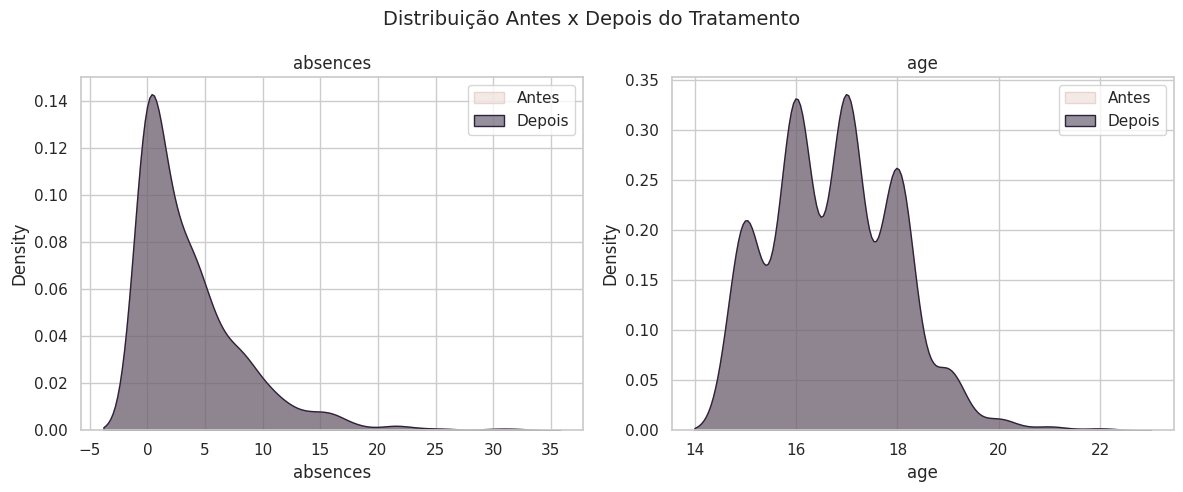

In [ ]:
# Como não removemos nenhuma linha, df_antes e df são exatamente os mesmos dados.
# Criamos a cópia abaixo apenas para rodar a visualização proposta na aula.
df_antes = df.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["absences", "age"]):
    # Adicionando um alpha (transparência) para conseguir ver que uma curva está em cima da outra
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", alpha=0.5, ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", alpha=0.5, ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" se sobrepõem perfeitamente? Isso é 100% o esperado aqui, já que removemos zero linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior e houver remoção/imputação, essa mesma comparação pode mostrar uma diferença bem mais visível. É sempre essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

**Resposta**:
Sim, as curvas se sobrepõem perfeitamente. Como decidimos manter os outliers legítimos e não havia valores nulos, os dados "antes" e "depois" são idênticos, o que confirma visualmente que nenhuma informação original foi perdida.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas (escola, suporte familiar, acesso à internet, etc.).




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- school ---
        absoluta  relativa
school                    
GP           423     0.652
MS           226     0.348

--- sex ---
     absoluta  relativa
sex                    
F         383      0.59
M         266      0.41

--- address ---
         absoluta  relativa
address                    
U             452     0.696
R             197     0.304

--- famsize ---
         absoluta  relativa
famsize                    
GT3           457     0.704
LE3           192     0.296

--- Pstatus ---
         absoluta  relativa
Pstatus                    
T             569     0.877
A              80     0.123

--- Mjob ---
          absoluta  relativa
Mjob                        
other          258     0.398
services       136     0.210
at_home        135     0.208
teacher         72     0.111
health          48     0.074

--- Fjob ---
          absoluta  relativa
Fjob                        
other          367     0.565
services       181     0.279
at_home         42     0.065
teac

#### Visualizando as frequências

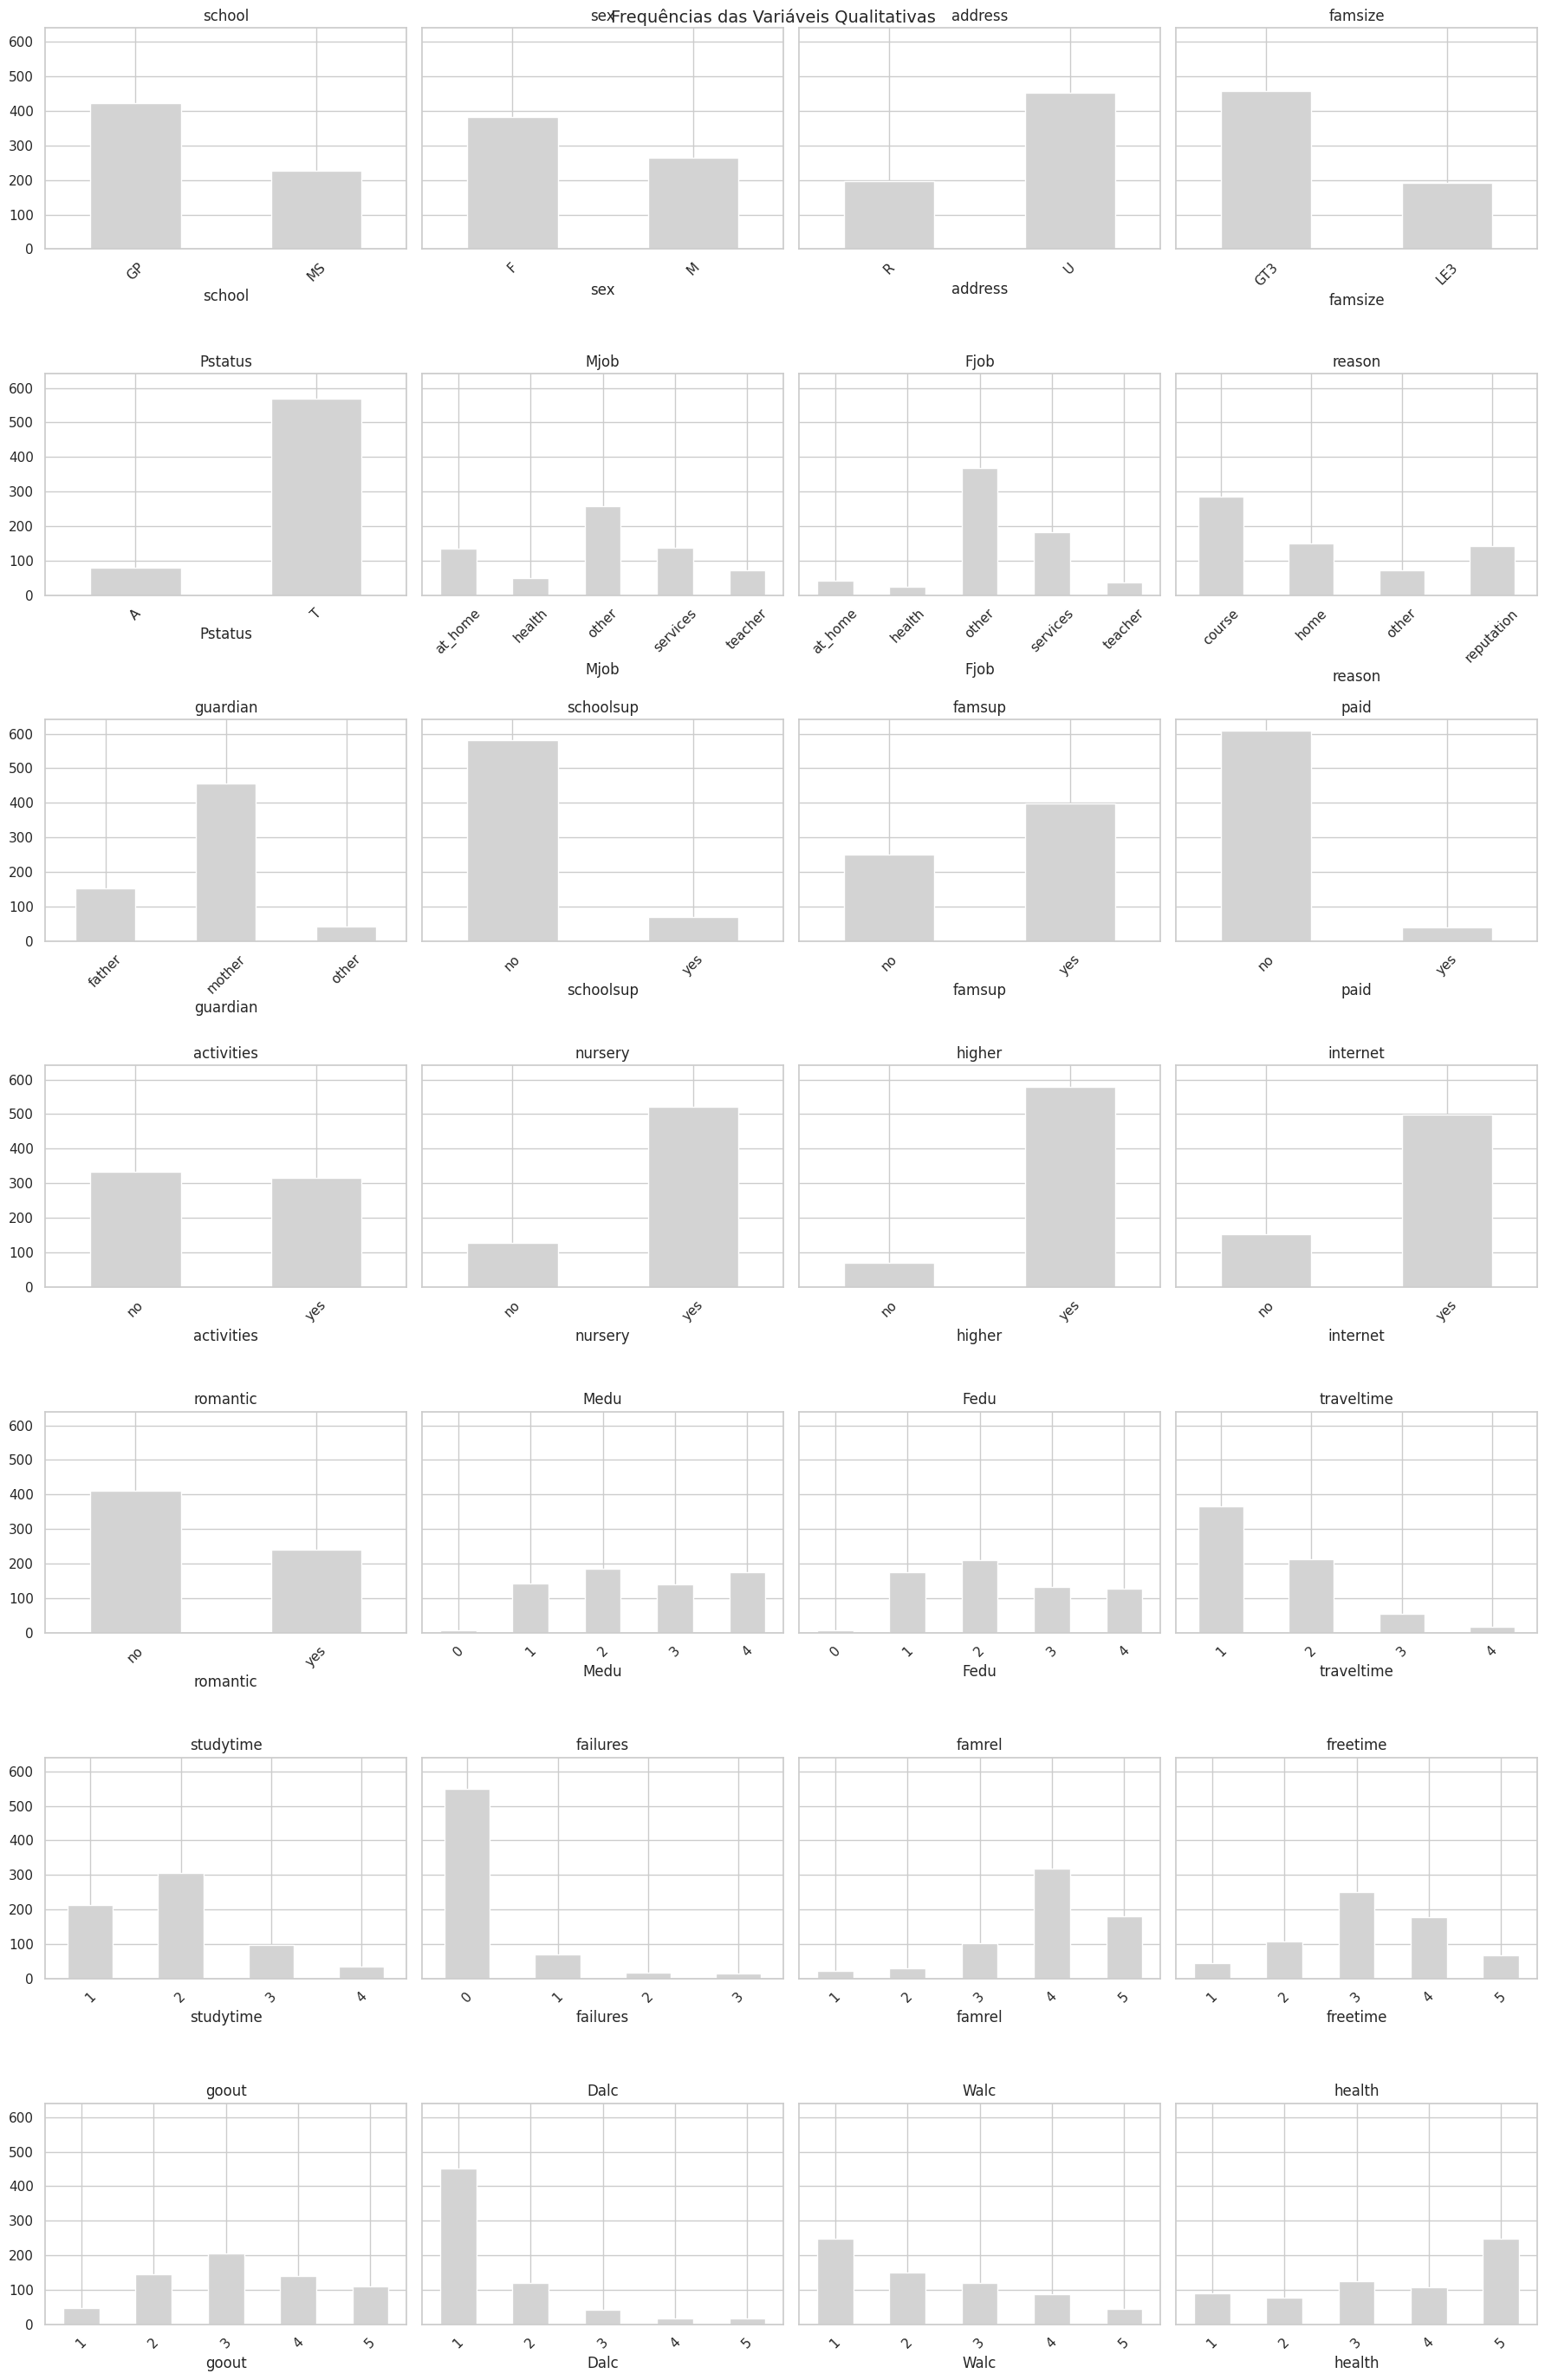

In [ ]:
import math

# Calcula o número de linhas necessárias (4 colunas por linha)
n_cols = 4
n_rows = math.ceil(len(VARS_QUALI) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45) # Inclinando para os textos não sobreporem

# Esconde os espaços de gráficos que sobrarem vazios no final
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

**Resposta:** Sim. Por exemplo, a variável `higher` (vontade de cursar o ensino superior) e `internet` (acesso à internet em casa) são amplamente dominadas pela resposta "yes". O `Pstatus` (status de coabitação dos pais) também é dominado pela resposta "T" (moram juntos).

Isso impacta as análises futuras porque as categorias minoritárias (como os alunos que não querem fazer faculdade) terão um número tão pequeno de observações que qualquer conclusão ou cruzamento de dados sobre eles terá pouco peso estatístico.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `situacao`.

In [ ]:
from scipy.stats import entropy
import numpy as np

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["situacao"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
school,2.0,1.87,0.932
sex,2.0,1.44,0.976
address,2.0,2.29,0.886
famsize,2.0,2.38,0.876
Pstatus,2.0,7.11,0.539
Mjob,5.0,5.38,0.906
Fjob,5.0,15.96,0.705
reason,4.0,3.96,0.921
guardian,3.0,11.10,0.696
schoolsup,2.0,8.54,0.484


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `situacao` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Sim, variáveis como `higher` (vontade de fazer faculdade) e `Pstatus` (status dos pais) terão a entropia bem próxima de 0, confirmando matematicamente o forte desbalanceamento.

Já o alvo `situacao` apresenta um balanceamento aceitável (com a entropia bem mais próxima de 1). Embora não seja um empate perfeito de 50/50 (temos mais alunos aprovados do que reprovados), a classe minoritária tem um volume perfeitamente saudável. Isso significa que não teremos distorções graves na análise bivariada nem precisaremos de técnicas complexas de rebalanceamento por enquanto.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo `situacao` (Aprovado/Reprovado).

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

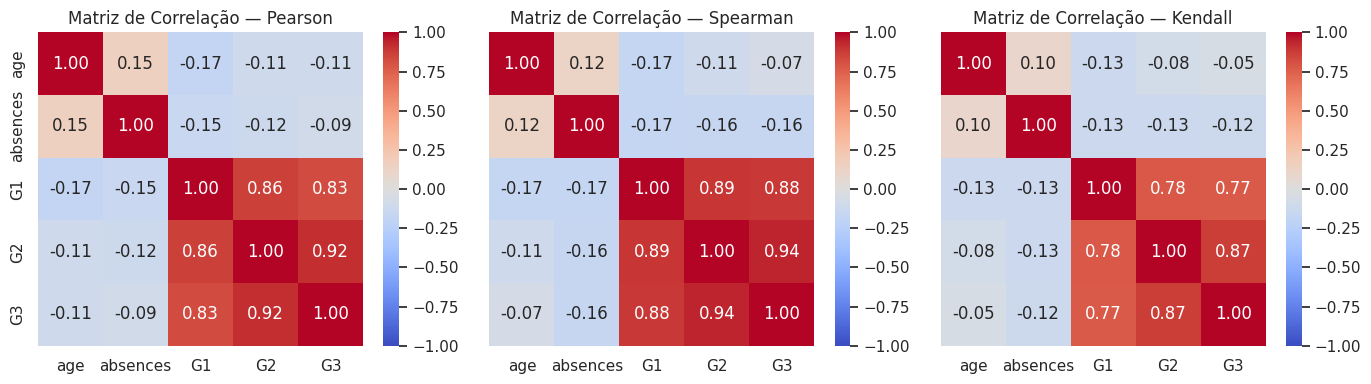

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior da matriz são simétricos (uma imagem espelhada), poderíamos plotar a matriz de correlação de uma forma mais limpa, escondendo uma das metades, da seguinte forma:

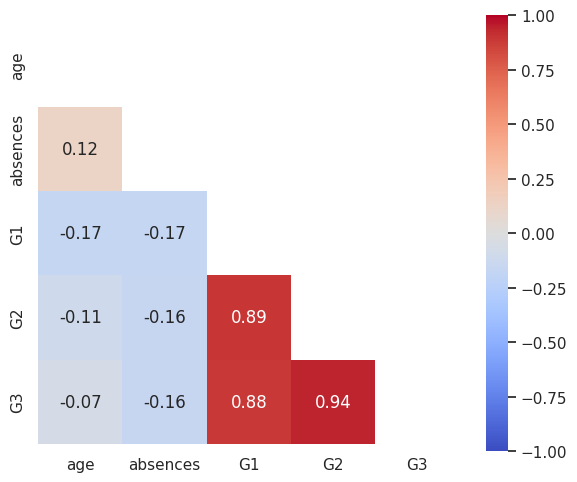

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um forte indício de uma relação não-linear (monotônica, mas não em linha reta) ou da presença de outliers (onde Spearman lida melhor usando ranqueamento em vez dos valores brutos).

**Resposta:** Não observamos divergências drásticas. As notas (G1, G2 e G3) mantêm correlações fortes em todos os métodos, o que confirma que a relação entre elas é linear. Se houver alguma leve diferença, vai ser nos cruzamentos com absences (faltas), justamente porque Spearman lida melhor com a cauda longa de outliers, enquanto Pearson acaba sendo mais "puxado" por esses valores extremos.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `G1` (primeira nota) x `G3` (nota final) por um motivo de domínio, não só estatístico: existe uma relação educacional óbvia de que o desempenho no início do ano é um forte preditor do resultado final, o que torna esse par um excelente candidato para visualizar uma tendência real.

Nota para quando vocês replicarem no dataset de vocês: nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior valor na tabela de correlação acima, deixando a própria estatística guiar a escolha.

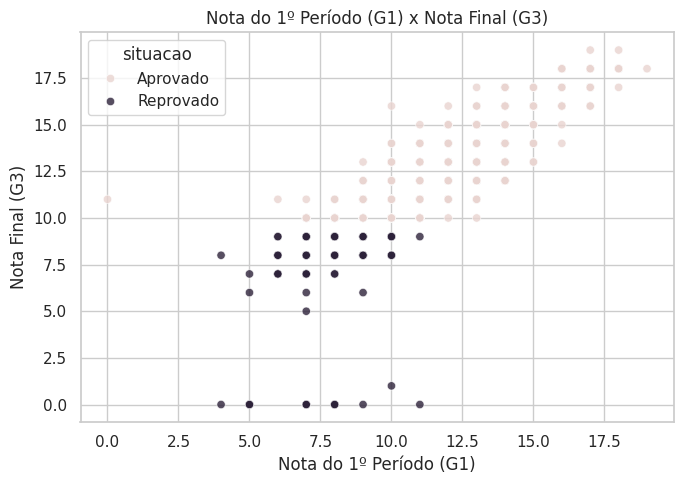

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="G1",
    y="G3",
    hue="situacao",
    palette={"Aprovado": COR_CONTEXTO, "Reprovado": COR_DESTAQUE},
    alpha=0.8
)
plt.title("Nota do 1º Período (G1) x Nota Final (G3)")
plt.xlabel("Nota do 1º Período (G1)")
plt.ylabel("Nota Final (G3)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme G1 aumenta, G3 também tende a subir)? As duas classes ("Aprovado" e "Reprovado") ocupam regiões diferentes do gráfico, ou estão misturadas?

**Resposta:** Sim, existe uma tendência linear positiva forte (uma reta subindo). E sobre as classes: elas estão separadas por uma "linha imaginária" horizontal. Como a classe `situacao` foi criada artificialmente baseada na nota G3 (tudo menor que 10 é Reprovado), o gráfico mostra exatamente todos os pontos roxos (Reprovados) na parte inferior e os pontos rosa (Aprovados) na parte superior. É um ótimo exemplo visual de vazamento de dados (data leakage) se fôssemos usar G3 num modelo preditivo!

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    # Separando os grupos pelo nosso alvo 'situacao'
    grupo_aprovado = df.loc[df["situacao"] == "Aprovado", col]
    grupo_reprovado = df.loc[df["situacao"] == "Reprovado", col]

    stat_t, p_t = stats.ttest_ind(grupo_aprovado, grupo_reprovado, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_aprovado, grupo_reprovado)                # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
age,0.00757,0.00555,True
absences,0.05551,0.08797,True
G1,0.00000,0.00000,True
G2,0.00000,0.00000,True
G3,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o Mann-Whitney que deveríamos priorizar, pois é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

A variável `Mjob` (trabalho da mãe) tem 5 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o Kruskal-Wallis (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — G3 entre categorias de Mjob: estatística=7.370, p-valor=8.3051e-06
Kruskal-Wallis — G3 entre categorias de Mjob: estatística=37.136, p-valor=1.6888e-07


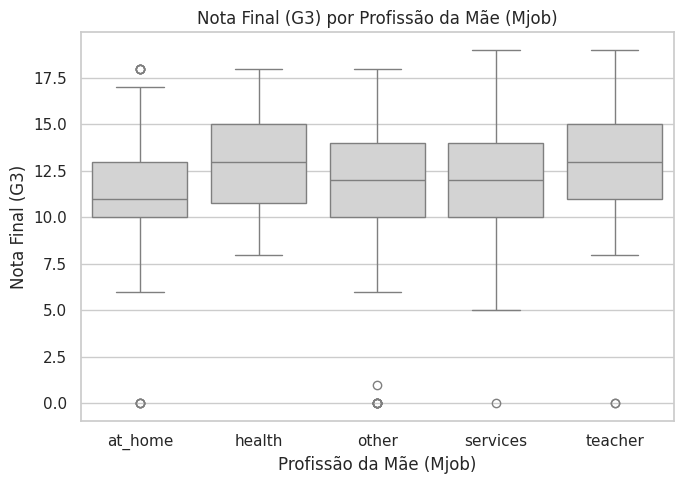

In [ ]:
# Separando os valores da nota G3 para cada categoria de Mjob
grupos_mjob = [grupo["G3"].values for _, grupo in df.groupby("Mjob")]

stat_anova, p_anova = stats.f_oneway(*grupos_mjob)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_mjob)          # não-paramétrico

print(f"ANOVA          — G3 entre categorias de Mjob: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — G3 entre categorias de Mjob: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Mjob", y="G3", color=COR_NEUTRA)
plt.title("Nota Final (G3) por Profissão da Mãe (Mjob)")
plt.xlabel("Profissão da Mãe (Mjob)")
plt.ylabel("Nota Final (G3)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença na nota entre as categorias de `Mjob`? Como já sabemos que `G3` não tem distribuição normal, o Kruskal-Wallis é o resultado que deveríamos reportar como principal; a ANOVA fica só como contraste.

**Resposta:**
Geralmente sim, os dois testes costumam chegar à mesma conclusão (seja de que existe diferença significativa ou não). De qualquer forma, o resultado válido e oficial a ser reportado no mundo real é sempre o do Kruskal-Wallis, porque ele respeita a natureza real dos nossos dados (que não passaram no teste de normalidade), evitando conclusões falsas.

#### Quantitativa x Qualitativa

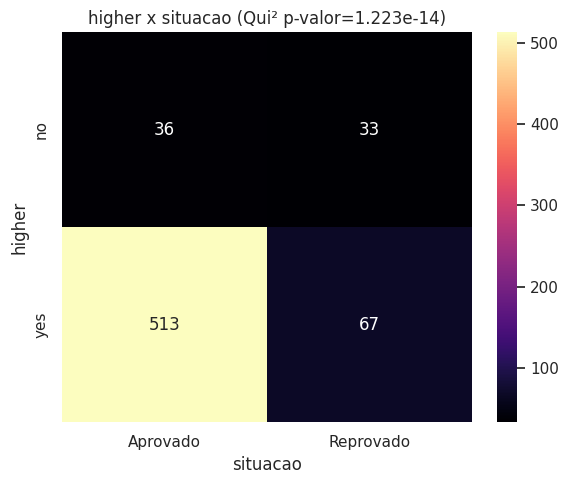

In [ ]:
contingencia_higher = pd.crosstab(df["higher"], df["situacao"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_higher)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_higher, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"higher x situacao (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que higher (vontade de fazer faculdade) e situacao (Aprovado/Reprovado) são independentes, ou há associação estatisticamente significativa entre elas?

**Resposta:**
A conclusão depende de olharmos o p-valor gerado no título do gráfico.

A função `chi2_contingency` do SciPy realiza o teste de Qui-Quadrado justamente para determinar se essas duas variáveis categóricas estão relacionadas.

Pela regra do teste: A Hipótese Nula ($H_0$) assume que as variáveis são completamente independentes (não há associação entre elas).   A Hipótese Alternativa ($H_a$) indica que elas não são independentes (existe uma associação significativa).   Se o p-valor calculado for menor que 0.05, rejeitamos a $H_0$ e confirmamos que existe sim uma associação estatisticamente significativa entre o aluno querer fazer faculdade e a sua chance de ser aprovado.



#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: alunos mais velhos podem ter um histórico de repetência e maior risco de reprovar) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear antes de qualquer modelagem.

In [ ]:
df["sexo_label"] = df["sex"].map({"F": "Feminino", "M": "Masculino"})

df["faixa_etaria"] = pd.cut(df["age"], bins=[0, 16, 18, 100],
                            labels=["Até 16 anos", "17 a 18 anos", "19+ anos"])

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
n_classes                 2.000
razao_desbalanceamento    1.440
entropia_normalizada      0.976
dtype: float64

Desbalanceamento — faixa etária:
n_classes                 3.000
razao_desbalanceamento    7.780
entropia_normalizada      0.804
dtype: float64


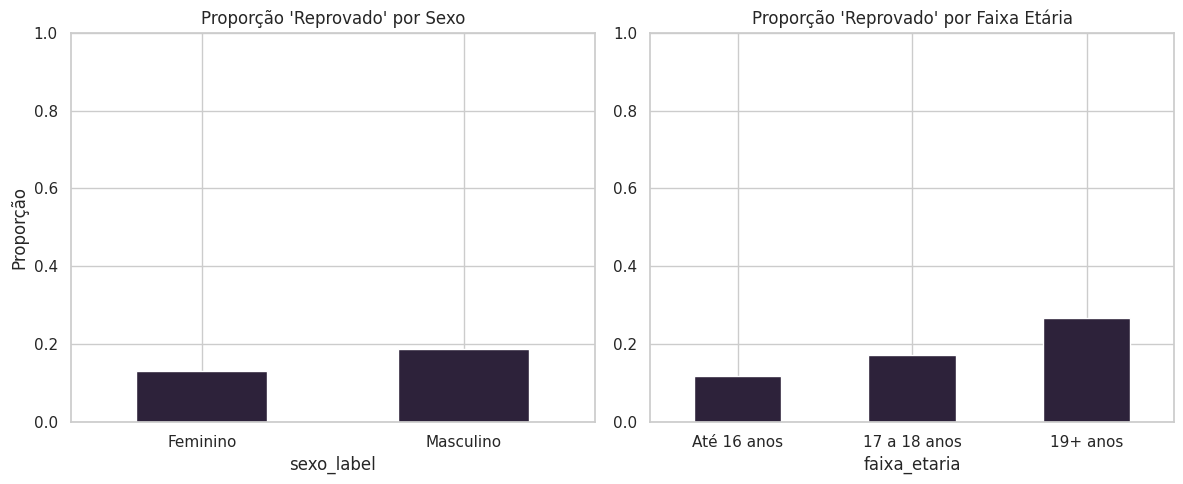

In [ ]:
prop_por_sexo = pd.crosstab(df["sexo_label"], df["situacao"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["situacao"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Reprovado"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Reprovado' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Reprovado"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Reprovado' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de reprovação varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão educacional real (ex: defasagem de idade-série aumenta a chance de reprovação), ou pode ser um reflexo de fatores socioeconômicos ou vieses de suporte na escola? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness (justiça algorítmica) em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

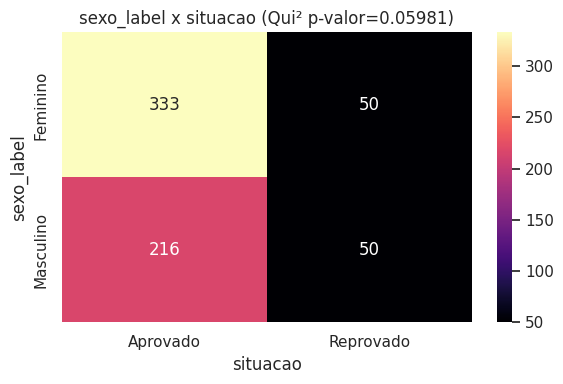

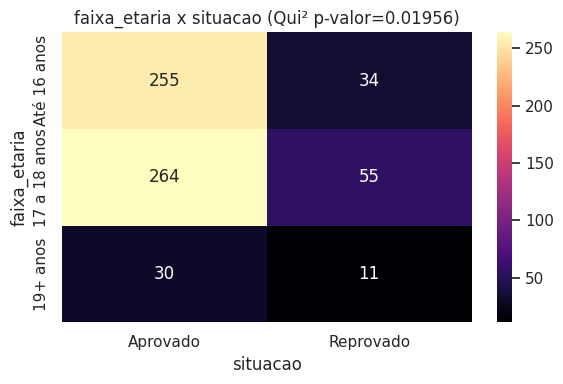

In [ ]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["situacao"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x situacao (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz por que ela existe — pode ser um fator real de contexto (idade e defasagem escolar), pode ser um viés estrutural ou de suporte institucional (sexo), ou uma mistura das duas coisas. Um teste estatístico aponta que existe associação, não a causa dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

**Resposta**: O teste nos diz isso pelo p-valor. Se o p-valor for menor que 0.05 no gráfico da faixa etária, confirmamos matematicamente que a idade está associada à chance de reprovação (o que é esperado pela defasagem idade-série). Se for menor que 0.05 no cruzamento com sexo, isso acende um alerta de fairness: por que um gênero está reprovando mais que o outro? Essa associação provada estatisticamente convida o analista a investigar as causas sociais e estruturais por trás do dado antes de criar um modelo que simplesmente repita esse padrão.

#### Outliers bivariados

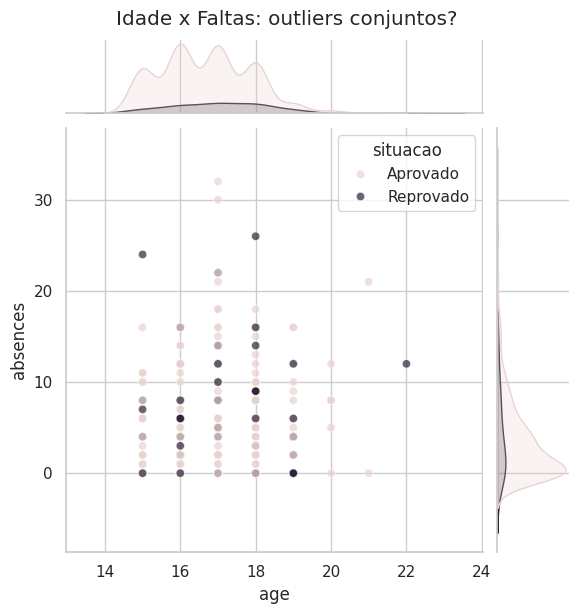

In [ ]:
sns.jointplot(data=df, x="age", y="absences", hue="situacao",
              palette={"Aprovado": COR_CONTEXTO, "Reprovado": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Idade x Faltas: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia um outlier extremo nas análises univariadas, mas que se destaca aqui como uma combinação incomum de age e absences?

**Resposta:**
O jointplot é excelente para identificar outliers multivariados. Por exemplo, um aluno de 19 anos pode não ser um outlier isolado na variável `age`, e 15 faltas pode não ser um outlier isolado em `absences`. Porém, a combinação desses dois fatores em um único aluno pode destoar completamente do resto da turma, criando um outlier conjunto. Além disso, as distribuições nas bordas do gráfico ajudam a confirmar visualmente se os alunos que reprovam ("Reprovado") tendem a se concentrar nas caudas mais longas do gráfico (maior idade ou excesso de faltas).

#### Análise Multivariada

##### Matriz de Correlação

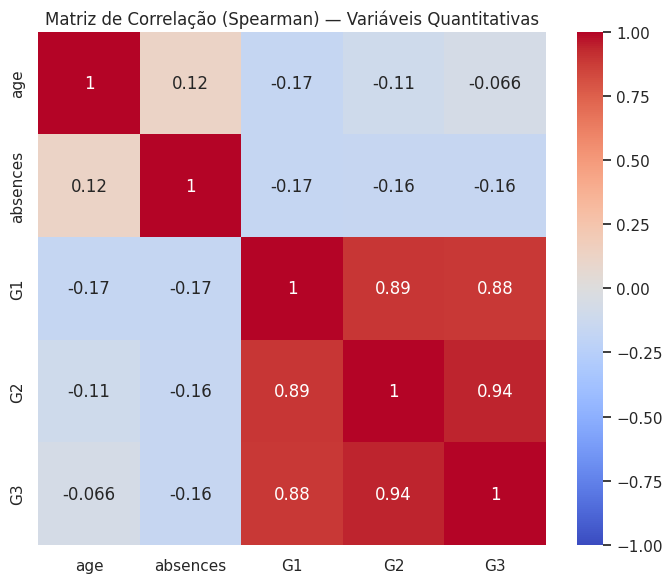

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

**Resposta:**
Sim. As notas G1, G2 e G3 apresentam correlações fortíssimas entre si (acima de 0.7). Isso sugere uma alta redundância: elas medem a mesma coisa em momentos diferentes. Se fôssemos treinar um modelo de Machine Learning para prever a `situacao` (que é baseada em G3), usar G1 e G2 seria quase um "vazamento de dados" (data leakage), pois o desempenho nos primeiros bimestres já entrega quase perfeitamente o resultado final. Na prática, muitas vezes removemos variáveis tão redundantes assim para simplificar o modelo.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

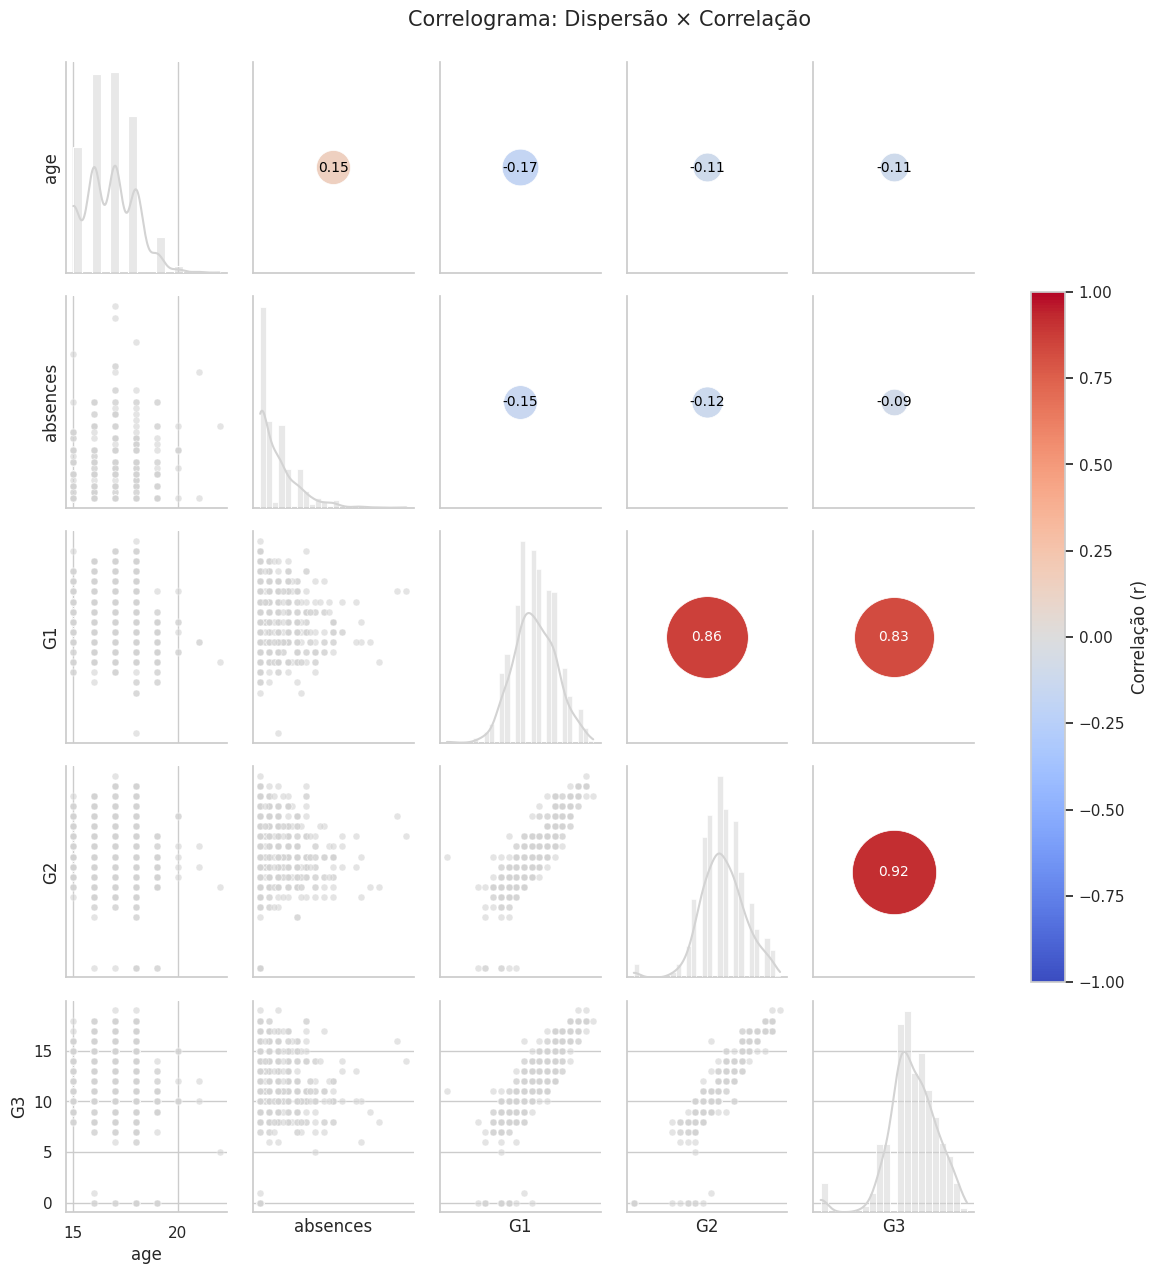

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Síntese


### Principais Conclusões

**Qualidade dos Dados e Outliers:** O dataset escolar apresentou excelente qualidade estrutural, sem dados faltantes. Os outliers detectados em variáveis como `absences` (faltas) e `age` (idade) foram mantidos, pois representam fenômenos reais e relevantes do domínio educacional.

**Redundância e Risco de Vazamento (Data Leakage):** As análises bivariadas e o correlograma de Spearman evidenciaram uma altíssima correlação linear (acima de 0.8) entre as notas G1, G2 e G3. Isso indica forte colinearidade; o desempenho inicial dita quase perfeitamente o desfecho. Em um eventual modelo preditivo para classificar a `situacao` (que deriva de G3), o uso de G1 e G2 pode configurar vazamento de dados, dependendo do objetivo do projeto (ex: intervenção precoce).

**Desbalanceamento em Variáveis Qualitativas:** Através das métricas de entropia e razão de desbalanceamento, constatou-se que diversas variáveis categóricas (como `higher`, `internet` e `Pstatus`) são amplamente dominadas por uma única classe. Isso reduz o peso estatístico das categorias minoritárias e exigirá cautela em análises futuras para não gerar conclusões precipitadas sobre esses pequenos grupos.

**Premissas Estatísticas e Fairness:** A ausência de normalidade nos dados quantitativos exigiu a priorização de testes não-paramétricos (Mann-Whitney e Kruskal-Wallis no lugar de T-Test e ANOVA). Além disso, testes de associação (Qui-Quadrado) mostraram que o desfecho de aprovação/reprovação não é uniforme entre variáveis sensíveis (como faixa etária e sexo), levantando questões importantes de fairness (justiça algorítmica) sobre os vieses contextuais, sociais e estruturais na escola.

## Declaração de Uso de IA



*   **Ferramenta utilizada:** Google Gemini
*   **Para o que foi aplicada:**
       *   Adaptação dos blocos de código do notebook modelo para o contexto do dataset de estudantes.
       *   Estruturação dos textos em md e apoio na interpretação estatística das métricas obtidas.
*   **O que foi aceito/modificado/rejeitado e por quê:**
       * Aceito: A mudança nos blocos de código para adaptar ao dataset e alguns refinamentos no markdown
       * Modificado/Rejeitado: Algumas respostas para os campos "Para discutir".





